In [1]:
# === Google Colab 自動環境セットアップ ===
# ※ローカル環境では安全に無視され、Colab環境でのみ自動実行されます
import os, sys
repo_root = os.path.abspath(os.path.join(os.getcwd(), "..") if os.path.basename(os.getcwd()) == "4" else os.getcwd())
if repo_root not in sys.path:
    sys.path.insert(0, repo_root)

if 'google.colab' in str(get_ipython()):
    print("Google Colab 環境を検出しました。環境構築を開始します...")
    if not os.path.exists("study-mikanos"):
        !git clone https://github.com/miyayudai/study-mikanos.git
    %cd study-mikanos
    !pip install -q -r requirements.txt
    !pip install -q -e .
    !cmake -B build -S . > /dev/null && cmake --build build --target ch04_vtable_sim > /dev/null
    print("セットアップが完了しました。作業ディレクトリ:", os.getcwd())
else:
    print(f"ローカル実行環境です。(リポジトリルート: {repo_root})")


ローカル実行環境です。(リポジトリルート: /home/student/Documents/GitHub/study-mikanos)


# 4.4 vtable（仮想関数テーブル）と `__cxa_pure_virtual` の深層

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/miyayudai/study-mikanos/blob/main/4/4.4_Virtual_Method_Table_vtable.ipynb)

本節では、前節（4.3節）で導入した C++ オブジェクト指向プログラミング（OOP: *Object-Oriented Programming*）とポリモーフィズム（*Polymorphism*）の背後にある、**機械語・ABI（*Application Binary Interface*）・ハードウェアレベルの低レイヤ動作原理** を徹底的に解剖します。

---

### 🎯 本節の学習目標 (Learning Objectives)

1. **動的ディスパッチ（*Dynamic Dispatch / Late Binding*）の数理と物理構造**:
   - オブジェクト先頭に埋め込まれる不可視メンバ `_vptr`（*Virtual Table Pointer*）と `vtable`（*Virtual Method Table*）のメモリ配置を理解する。
2. **Itanium C++ ABI の完全仕様**:
   - x86-64 Linux / Clang / GCC が準拠する Itanium C++ ABI における、負のオフセット（`offset-to-top`, RTTI `typeinfo`）と正のオフセット（デストラクタ、仮想関数スロット）の配置規則を導出する。
3. **x86-64 アセンブリレベルでの間接関数呼び出し（*Indirect Call*）**:
   - `pixel_writer->Write(x, y, color)` がどのような CPU 命令列（`mov rax, [rdi]`, `mov rax, [rax + 16]`, `call rax`）にコンパイルされ、System V AMD64 ABI レジスタ経由で実行されるかを追跡する。
4. **純粋仮想関数（*Pure Virtual Function*）と `__cxa_pure_virtual` の正体**:
   - なぜ抽象クラスの未実装スロットに `nullptr` ではなく `&__cxa_pure_virtual` が格納されるのか、そしてなぜベアメタル環境でリンクエラーが発生するのかを解明する。
5. **ベアメタル・OSカーネルにおける自前ランタイムスタブの実装**:
   - 標準ライブラリ不在のフリースタンディング環境でリンカを通し、万一の不正呼び出し時に CPU を安全に HLT 停止させる防衛設計を修得する。

---

### 🔍 動機と前節からの課題：魔法の正体を暴く

前節（4.3節）において、我々は以下のような抽象基底クラス `PixelWriter` と具象派生クラスを定義しました：

```cpp
class PixelWriter {
public:
    PixelWriter(const FrameBufferConfig& config) : config_{config} {}
    virtual ~PixelWriter() = default;
    virtual void Write(int x, int y, const PixelColor& c) = 0; // 純粋仮想関数
...
};

class RGBResv8BitPerColorPixelWriter : public PixelWriter {
public:
    using PixelWriter::PixelWriter;
    virtual void Write(int x, int y, const PixelColor& c) override { ... }
};
```

呼び出し側では、基底クラスのポインタ `PixelWriter* pixel_writer;` を通じて単に次のように呼ぶだけで、ピクセルフォーマットに応じた正しい描画関数が実行されました：

```cpp
pixel_writer->Write(x, y, {255, 255, 255});
```

しかし、CPU はハードウェアとして「クラス」や「継承」という概念を一切持ちません。CPU が理解できるのは、レジスタ、メモリ番地、そして `JMP` や `CALL` などの機械語命令だけです。

では、**`pixel_writer->Write(...)` という1行のコードは、CPU のメモリとレジスタの上で一体どのように実行されているのでしょうか？**
また、ベアメタル環境でビルドした際、なぜリンカは聞き慣れない `undefined reference to '__cxa_pure_virtual'` というエラーを突きつけてくるのでしょうか？

本節では、この「C++ のオブジェクト指向の裏側」を完全に可視化し、OS 開発者としてハードウェアの視点からマスターします。

```mermaid
flowchart TD
    subgraph Caller["呼び出し側 (Caller)"]
        A["pixel_writer->Write(x, y, c)"]
    end

    subgraph Object["オブジェクトインスタンス (16 Bytes)"]
        B["+0x00: _vptr (8 Bytes)"]
        C["+0x08: config_ 参照ポインタ (8 Bytes)"]
    end

    subgraph VTable["仮想関数テーブル (vtable in .rodata)"]
        D["-0x10: offset-to-top (0)"]
        E["-0x08: RTTI typeinfo ポインタ"]
        F["+0x00: Complete Object Destructor"]
        G["+0x08: Deleting Destructor"]
        H["+0x10: Write() 実装アドレス"]
    end

    subgraph TargetFunc["具象関数実体 (.text)"]
        I["RGBResv8BitPerColorPixelWriter::Write()"]
    end

    A -->|"1. RDI (this) 参照"| B
    B -->|"2. vptr の指す先へ間接参照"| F
    F -.->|"オフセット +16B"| H
    H -->|"3. 間接ジャンプ (call rax)"| I
```


## 1. 仮想関数テーブル (vtable) と vptr の構造力学

### 仮想関数の動的ディスパッチ（*Dynamic Dispatch*）

通常のメンバ関数（非仮想関数）の呼び出しは、コンパイル時に呼び出す関数のメモリアドレスが静的に決定されます（**静的結合 / Early Binding**）。機械語としては固定アドレスへの `call 0x401200` となり、実行時のオーバーヘッドはゼロです。

一方、`virtual` キーワードが付与された関数（仮想関数）は、ポインタが実行時に実際に指しているオブジェクトの型（`RGB...Writer` なのか `BGR...Writer` なのか）に応じて、実行時に呼び出す関数を切り替える必要があります（**動的結合 / Late Binding**）。

これを実現するため、C++ コンパイラは以下の 2 つの仕掛けを自動生成します：

1. **`vtable`（*Virtual Method Table* / 仮想関数テーブル）**:
   - 仮想関数を持つクラスごとに、コンパイラが読み取り専用データセクション（`.rodata`）内に 1 つだけ生成する **関数ポインタの静的配列**。
2. **`_vptr`（*Virtual Table Pointer* / 仮想テーブルポインタ）**:
   - 仮想関数を持つクラスの各インスタンスの **先頭（オフセット 0）** に、コンパイラが不可視メンバ変数として自動的に挿入する 64 ビット（8バイト）のポインタ。
   - コンストラクタが実行される際、そのオブジェクトのクラスに対応する `vtable` の先頭アドレスが自動的に代入される。

---

### Itanium C++ ABI におけるメモリレイアウト

x86-64 アーキテクチャの Linux、FreeBSD、macOS、および Clang/GCC コンパイラは、業界標準規格である **Itanium C++ ABI** に準拠しています。

Itanium C++ ABI では、`vptr` が指すアドレスを基準点（オフセット `0`）とし、**正のオフセットだけでなく負のオフセットにも重要なメタデータ** を配置します：

| オフセット | 格納内容 | 役割・説明 |
|:---:|---|---|
| **`-16` (`-0x10`)** | `offset-to-top` | 派生クラス先頭から完全オブジェクト先頭へのオフセット（単一継承では常に `0`） |
| **`-8` (`-0x08`)** | `typeinfo pointer` | 実行時型情報（RTTI: *Run-Time Type Information*, `std::type_info`）へのポインタ（`-fno-rtti` 時は null または最小構造） |
| **`+0` (`+0x00`)** | Complete Object Destructor | `_vptr` が指す基準点。オブジェクト自身を破棄するデストラクタの関数ポインタ |
| **`+8` (`+0x08`)** | Deleting Destructor | オブジェクトを破棄した後にメモリ解放（`operator delete`）を呼び出すデストラクタ |
| **`+16` (`+0x10`)** | 第1仮想関数 (`Write`) | クラス内で最初に宣言された仮想関数のポインタ（`PixelWriter::Write`） |

> [!IMPORTANT]
> **なぜオブジェクトサイズが 16 バイトになるのか？**
> `PixelWriter` の定義にはメンバ変数として `const FrameBufferConfig& config_`（ポインタ実体 8 バイト）しか書かれていません。
> しかし、仮想関数を 1 つでも宣言した瞬間、コンパイラが先頭に 8 バイトの `_vptr` を不可視メンバとして追加するため：
> $$	ext{sizeof}(	ext{PixelWriter}) = 	ext{sizeof}(\_vptr) + 	ext{sizeof}(config\_) = 8 + 8 = 16 	ext{ Bytes}$$
> となります。前節で `char pixel_writer_buf[sizeof(RGBResv8BitPerColorPixelWriter)]` として確保した 16 バイトのメモリ空間には、まさにこの `_vptr` と `config_` が収まっていたのです！


In [2]:
# Python シミュレーションによる Itanium C++ ABI vtable とメモリ配置の完全検証
import struct
from common import (
    ItaniumAbiVTableSimulator,
    PolymorphicObjectLayout,
    VPtrInspector,
    PureVirtualCallError
)

sim = ItaniumAbiVTableSimulator()

print("=== 1. クラスごとの vtable 静的構造 ===")
for class_name, vt in sim.vtables.items():
    print(f"\n[vtable for {class_name}] (Base Address: 0x{vt.vtable_base_address:08x})")
    for entry in vt.entries:
        sign = "+" if entry.offset_bytes >= 0 else ""
        trap_flag = " [TRAP!]" if entry.is_pure_virtual else ""
        print(f"  Slot {sign}{entry.offset_bytes:>3}B: 0x{entry.target_address:08x} -> {entry.symbol_name:<40} ({entry.description}){trap_flag}")

print("\n=== 2. インスタンスのメモリ構造 (PolymorphicObjectLayout) ===")
rgb_obj = sim.create_instance("RGBResv8BitPerColorPixelWriter", instance_address=0x00100000)
print(rgb_obj.format_memory_map())


=== 1. クラスごとの vtable 静的構造 ===

[vtable for PixelWriter] (Base Address: 0x00403000)
  Slot -16B: 0x00000000 -> offset-to-top                            (Offset to complete object (0))
  Slot  -8B: 0x00403f00 -> _ZTI11PixelWriter                        (std::type_info for PixelWriter)
  Slot +  0B: 0x00401050 -> _ZN11PixelWriterD1Ev                     (Complete object destructor)
  Slot +  8B: 0x00401070 -> _ZN11PixelWriterD0Ev                     (Deleting destructor)
  Slot + 16B: 0x00401ff0 -> __cxa_pure_virtual                       (Pure virtual function trap!) [TRAP!]

[vtable for RGBResv8BitPerColorPixelWriter] (Base Address: 0x00403100)
  Slot -16B: 0x00000000 -> offset-to-top                            (Offset to complete object (0))
  Slot  -8B: 0x00403f20 -> _ZTI30RGBResv8BitPerColorPixelWriter     (typeinfo for RGB writer)
  Slot +  0B: 0x00401100 -> _ZN30RGBResv8BitPerColorPixelWriterD1Ev  (Complete object destructor)
  Slot +  8B: 0x00401120 -> _ZN30RGBResv8BitPerColorPixe

## 2. アーキテクチャ図版: vtable メモリレイアウトと間接ディスパッチ

以下の図版（Figure 4.7）は、Itanium C++ ABI に基づくオブジェクトメモリ構造、`.rodata` セクション内の vtable スロット配置、および CPU レジスタによる 3 段階の間接呼び出しパイプラインを精密に可視化したものです。


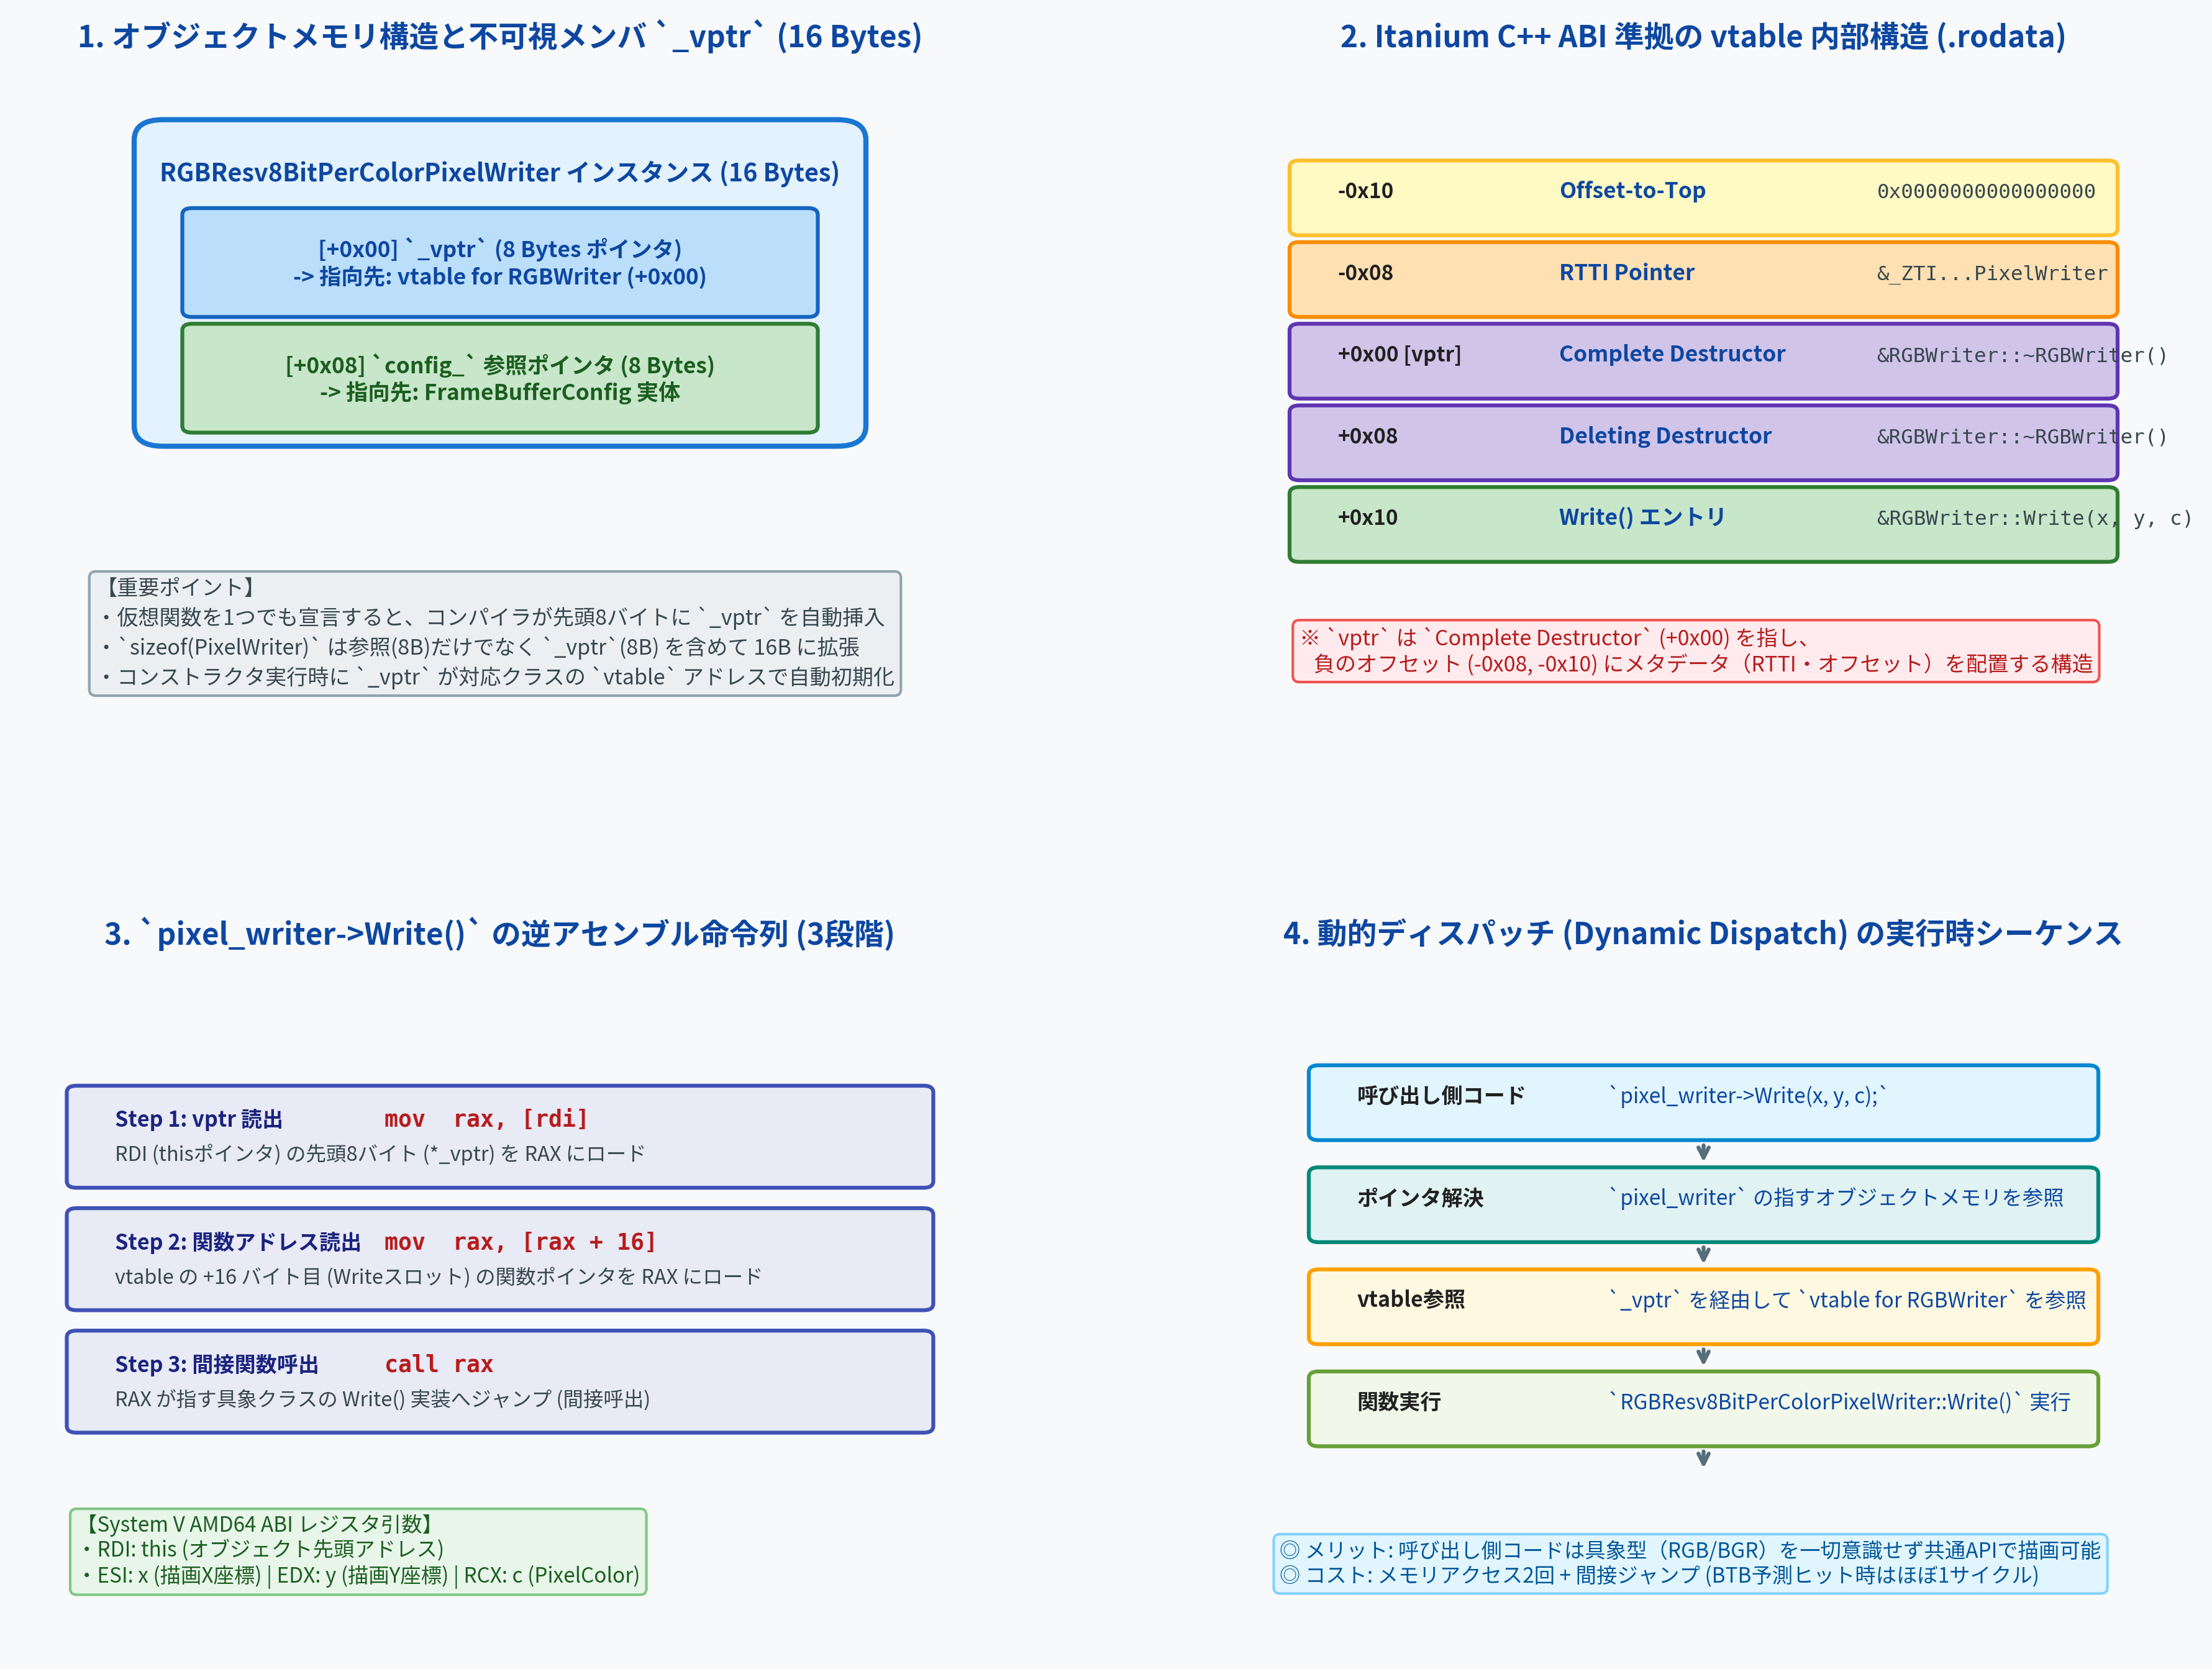

In [3]:
from IPython.display import Image, display
display(Image(filename="result/fig4_07_vtable_memory_layout_and_dispatch.png"))


## 3. x86-64 アセンブリ解剖：間接関数呼び出しの機械語命令列

C++ コードにおける多態的な関数呼び出し：
```cpp
pixel_writer->Write(x, y, color);
```
がコンパイラ（Clang / GCC）によってどのような x86-64 機械語命令に変換されるかを、System V AMD64 ABI のレジスタ呼び出し規約とともに詳細に確認します。

### レジスタの初期状態 (Calling Convention)
- `RDI`: 暗黙の第1引数 `this` ポインタ（`pixel_writer` のアドレス、すなわち `pixel_writer_buf`）
- `ESI`: 第2引数 `x` 座標（32ビット整数）
- `EDX`: 第3引数 `y` 座標（32ビット整数）
- `RCX`: 第4引数 `color`（値渡しまたは構造体参照）

### 3 段階の間接ディスパッチ命令列
```nasm
; Step 1: オブジェクト先頭から _vptr を読み出す
mov   rax, [rdi]        ; RAX = *(uintptr_t*)this (vtable のアドレス)

; Step 2: vtable のオフセット +16 (Writeスロット) から関数アドレスを読み出す
mov   rax, [rax + 16]   ; RAX = *(uintptr_t*)(RAX + 16) (具象Write関数の先頭アドレス)

; Step 3: レジスタ間接ジャンプで関数を実行
call  rax               ; RIP を RAX へジャンプし、戻りアドレスをスタックにプッシュ
```

この命令列から以下の重要な物理的挙動がわかります：
1. **メモリアクセスが2回発生する**:
   - 1回目: オブジェクト先頭から `_vptr` をロード（L1D キャッシュ）
   - 2回目: `vtable[2]` から関数アドレスをロード（L1D / .rodata キャッシュ）
2. **間接分岐命令（`call rax`）**:
   - 分岐先アドレスが命令自身の中に埋め込まれておらず、レジスタの値によって動的に決まる。
   - CPU の **BTB（*Branch Target Buffer* / 分岐先バッファ）** がこの間接ジャンプ先を予測学習する。


In [4]:
# Python シミュレータによる逆アセンブル命令列の動的生成
asm_steps = VPtrInspector.disassemble_indirect_call(method_offset=16)
print("=== x86-64 Indirect Call Assembly Trace ===")
for step in asm_steps:
    print("  ", step)

# 実際の動的ディスパッチを実行
addr, sym = sim.dispatch(rgb_obj, "Write", 100, 100, (0, 255, 0))
print(f"\n[Dispatch Result] Target Address: 0x{addr:08x} -> Symbol: {sym}")


=== x86-64 Indirect Call Assembly Trace ===
   mov   rax, [rdi]        ; Step 1: Dereference this pointer (RDI) -> load vptr into RAX
   mov   rax, [rax + 16]   ; Step 2: Index vtable at offset +16 -> load function address
   call  rax               ; Step 3: Indirect call to resolved virtual method

[Dispatch Result] Target Address: 0x00401200 -> Symbol: _ZN30RGBResv8BitPerColorPixelWriter5WriteEiiRK10PixelColor


## 4. 純粋仮想関数と `__cxa_pure_virtual` の真実

### 抽象基底クラスの vtable は存在するのか？

前節で登場した `PixelWriter` は純粋仮想関数 `virtual void Write(...) = 0;` を持っているため、**抽象基底クラス（*Abstract Base Class*）** です。C++ の言語仕様上、抽象クラスのインスタンスを直接生成することは禁止されています：

```cpp
PixelWriter writer{config}; // コンパイルエラー！抽象クラスは直接実体化できない
```

では、**「抽象基底クラス `PixelWriter` の vtable は、コンパイル後のバイナリに生成されるのでしょうか？」**

答えは **「YES」** です。
なぜなら、派生クラス `RGBResv8BitPerColorPixelWriter` のコンストラクタが実行される際、**基底クラス `PixelWriter` のコンストラクタが先に呼び出される** からです。
基底クラスのコンストラクタが実行されている間、オブジェクトの `_vptr` は一時的に **基底クラス `PixelWriter` の vtable** を指すようコンパイラが設定します。

---

### 純粋仮想スロットに何を入れるべきか？

基底クラス `PixelWriter` の vtable において、未実装の `Write` 関数のスロット（オフセット `+16`）には何が入るべきでしょうか？

- **もし `nullptr`（0番地）を入れたら？**:
  万が一、純粋仮想関数が呼び出された際、CPU はアドレス `0x00000000` へジャンプしてしまい、**ページフォールト（*Page Fault* / ヌルポインタデリファレンス）** で OS やプロセスが即死します。これでは「なぜクラッシュしたのか」のデバッグが極めて困難になります。
- **Itanium C++ ABI の賢明な解法**:
  Itanium C++ ABI では、純粋仮想関数のスロットには `nullptr` ではなく、特殊な例外・パニックハンドラ関数 **`__cxa_pure_virtual` の関数ポインタ** を格納すると定めています。

```text
+----------------------------------------------------------------------------------------------------+
| Itanium C++ ABI 純粋仮想スロット配置規約                                                            |
+----------------------------------------------------------------------------------------------------+
| 抽象クラス vtable for PixelWriter:                                                                 |
|   [+0x00] Complete Destructor -> &_ZN11PixelWriterD1Ev (基底デストラクタ)                           |
|   [+0x08] Deleting Destructor -> &_ZN11PixelWriterD0Ev                                             |
|   [+0x10] Write() エントリ    -> &__cxa_pure_virtual  <-- 万一呼ばれたら即座にトラップ！           |
+----------------------------------------------------------------------------------------------------+
```

---

### 純粋仮想関数が呼び出されてしまう「危険なシナリオ」

通常、派生クラスの構築が完了していれば `_vptr` は具象クラスの vtable を指しているため、`__cxa_pure_virtual` が呼ばれることはありません。
しかし、以下のようなコードを書くと、コンパイルをすり抜けて実行時に純粋仮想関数が呼び出されてしまいます（**Pure Virtual Function Call Trap**）：

```cpp
class PixelWriter {
public:
    PixelWriter(const FrameBufferConfig& config) : config_{config} {
        // 危険！基底クラスのコンストラクタ実行中は、まだ派生クラスが未構築！
        // この時点で this->_vptr は PixelWriter の vtable を指している！
        InitScreen(); 
    }

    void InitScreen() {
        Write(0, 0, {0, 0, 0}); // 間接的に純粋仮想関数を呼び出してしまう！
    }

    virtual void Write(int x, int y, const PixelColor& c) = 0;
};
```

このようなコードが実行されると、CPU は `PixelWriter` の vtable のスロット `+16` に格納されている `__cxa_pure_virtual()` を呼び出し、エラーメッセージを出力して安全にプログラムを終了させます。


In [5]:
# Python シミュレーションによる純粋仮想関数呼び出しトラップの再現
abstract_obj = sim.create_instance("PixelWriter", instance_address=0x00100000)

print("抽象基底クラス PixelWriter の vtable から Write() を強制ディスパッチします...")
try:
    sim.dispatch(abstract_obj, "Write", 0, 0, (255, 255, 255))
except PureVirtualCallError as e:
    print(f"\n[TRAP DETECTED] 期待通り例外を検知しました:\n  {e}")


抽象基底クラス PixelWriter の vtable から Write() を強制ディスパッチします...

[TRAP DETECTED] 期待通り例外を検知しました:
  FATAL: Pure virtual function call trap! Invoked slot '+16' (Write) on abstract class 'PixelWriter' -> __cxa_pure_virtual()


## 5. アーキテクチャ図版: `__cxa_pure_virtual` とベアメタルの洗礼

以下の図版（Figure 4.8）は、純粋仮想関数トラップの発生フロー、ホスト環境（`libc++abi`）とベアメタル（MikanOS）におけるリンク解決の決定的差異、および間接呼び出しのレイテンシ特性を総括したものです。


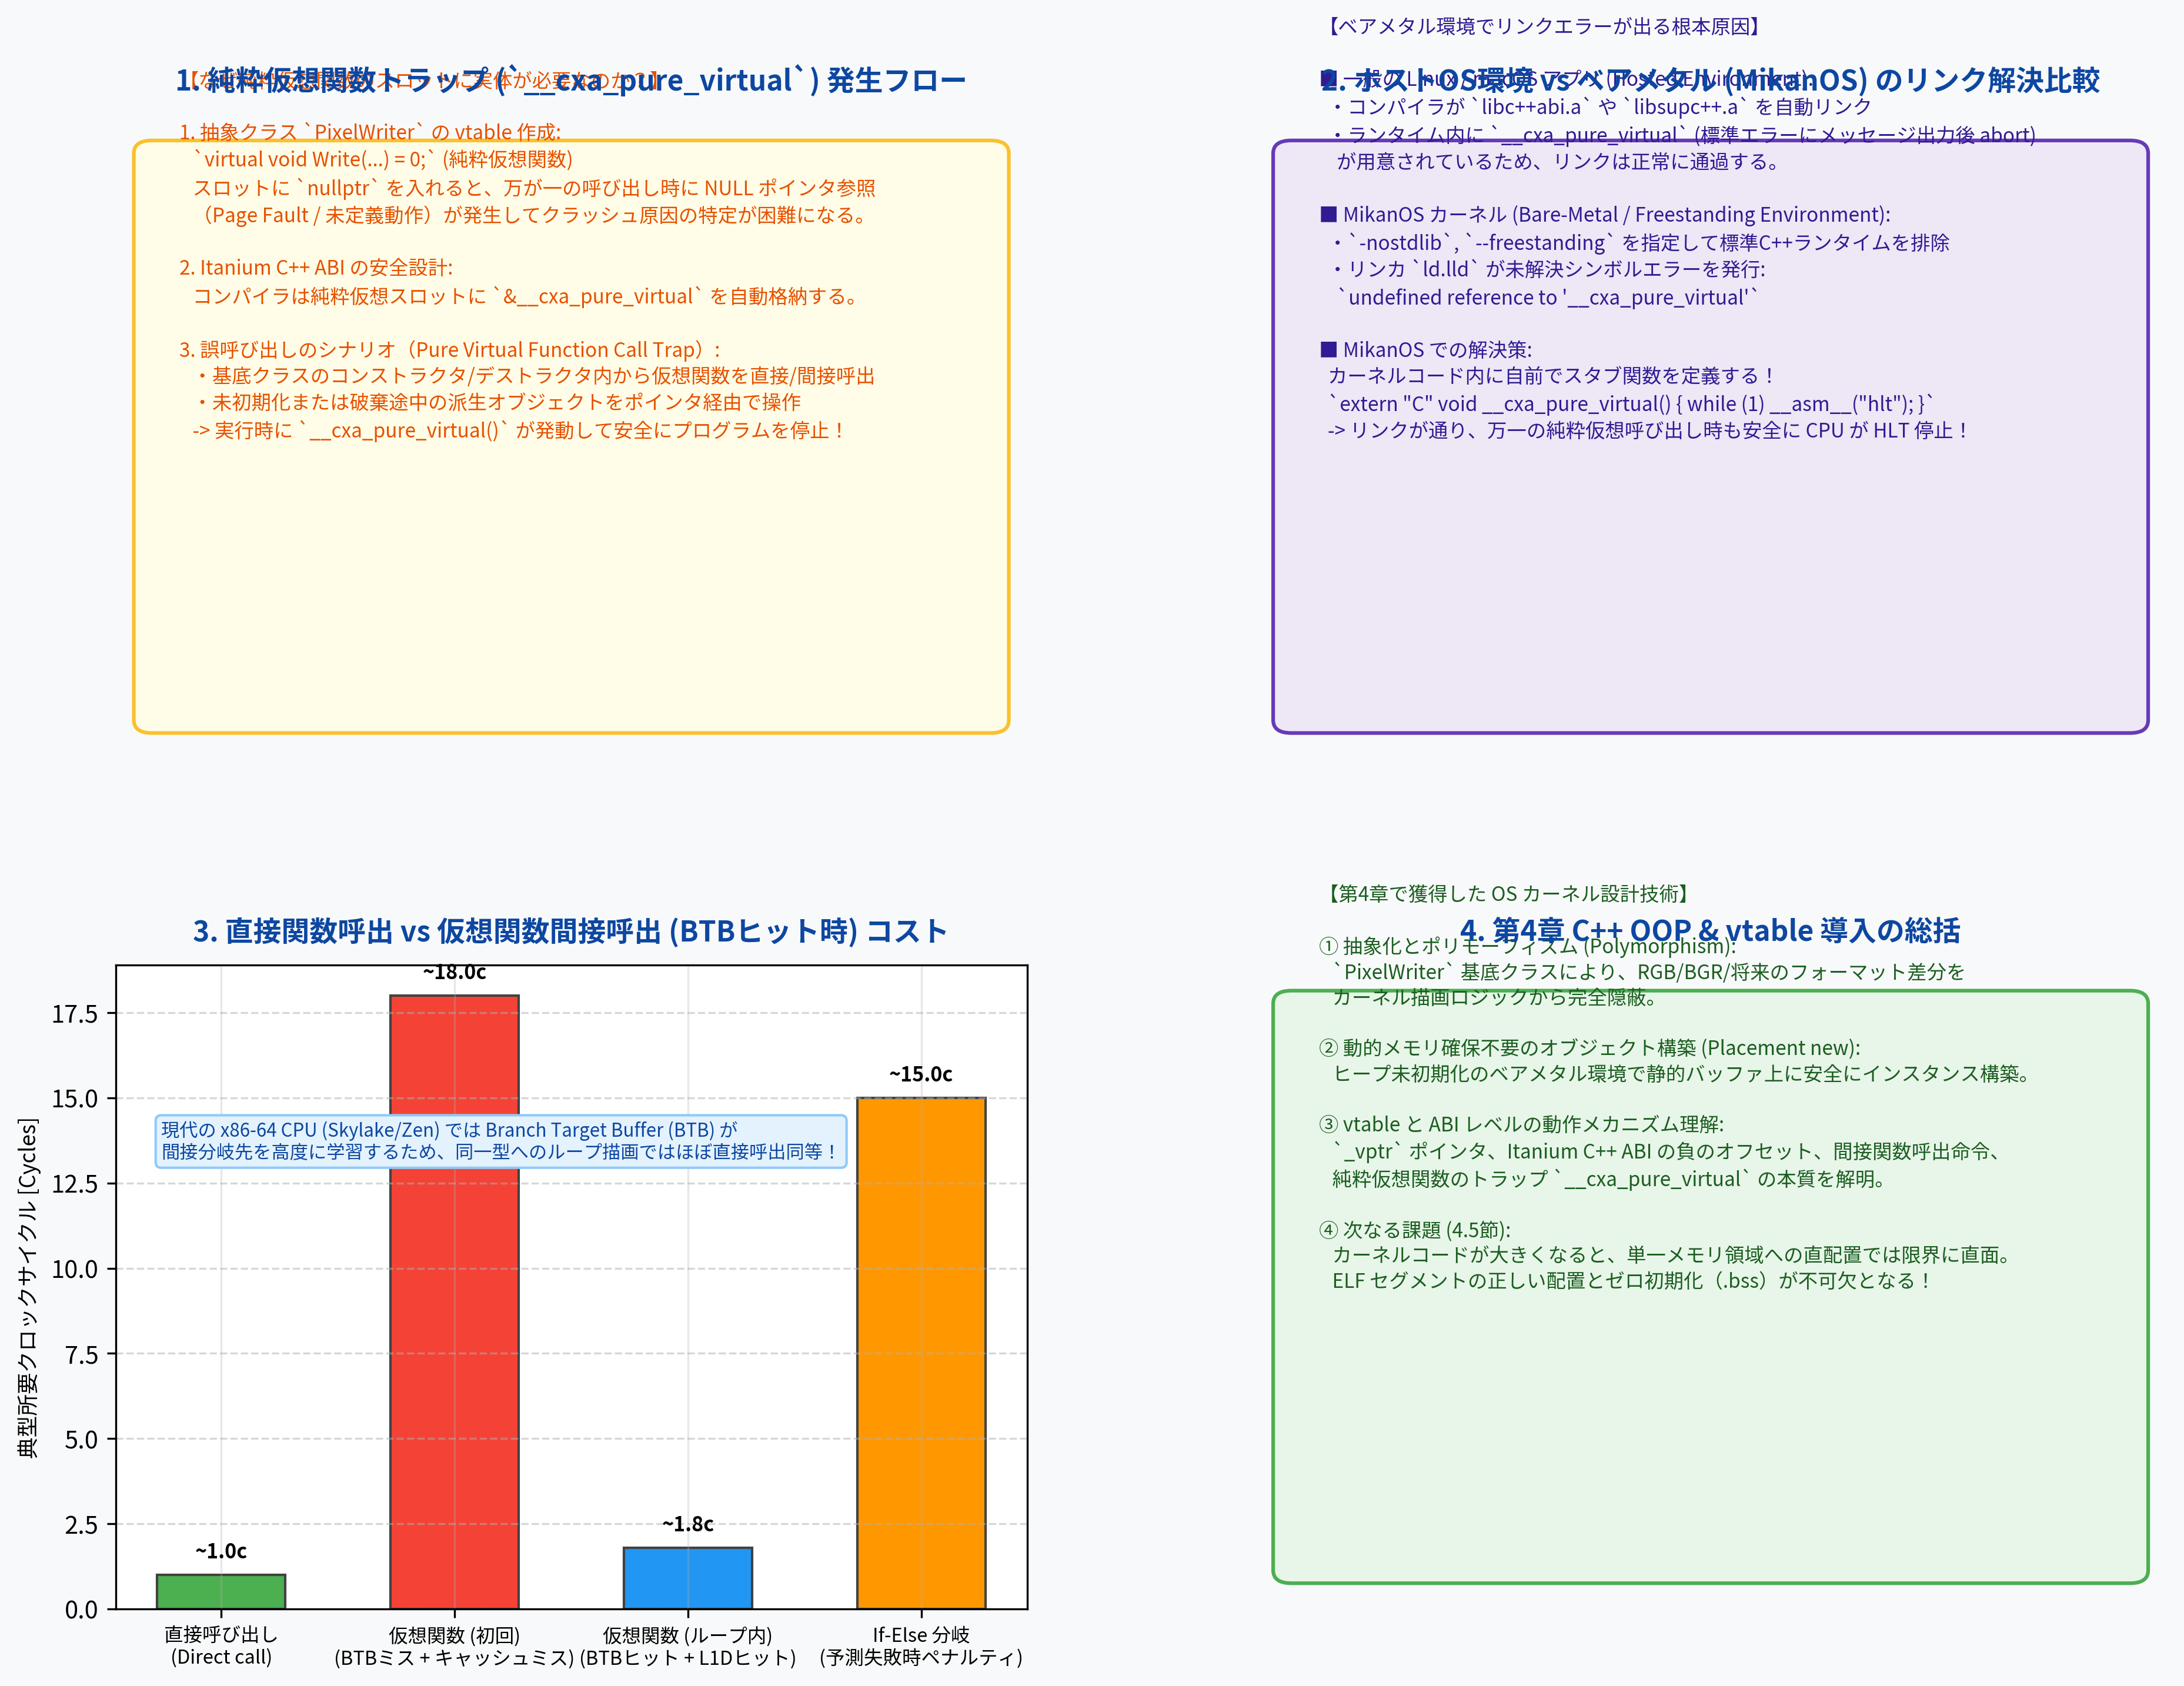

In [6]:
display(Image(filename="result/fig4_08_cxa_pure_virtual_and_abi.png"))


## 6. なぜベアメタル環境でリンクエラーになるのか？

### ホスト環境 vs フリースタンディング（自作OS）環境

普通の Linux や Windows 上で C++ アプリケーションを開発している場合、開発者が `__cxa_pure_virtual` を意識することはまずありません。なぜなら、コンパイラが自動的に C++ 標準ランタイムライブラリ（`libsupc++.a` や `libc++abi.a`）をリンクし、その中に以下のような実装が含まれているからです：

```cpp
// GCC / Clang 標準ランタイム (libsupc++ / libc++abi) の実装イメージ
extern "C" void __cxa_pure_virtual() {
    fputs("pure virtual method called\n", stderr);
    abort();
}
```

しかし、MikanOS カーネルのビルド環境は **ベアメタル・フリースタンディング環境** です：
- コンパイラオプションに `-nostdlib` や `--freestanding` を指定して、ホスト OS の標準ライブラリを一切遮断しています。
- リンカ `ld.lld` は、`PixelWriter` の vtable が要求する未解決シンボル `__cxa_pure_virtual` をどこからも見つけることができず、エラーを出して停止します：
  ```text
  ld.lld: error: undefined reference to '__cxa_pure_virtual'
  ```

---

### MikanOS カーネルでの自前スタブ実装

OS を自作するということは、**「ランタイムライブラリが提供していた低レイヤフックも自分自身で実装する」** ということです。
MikanOS では、カーネルソースコード（`main.cpp` やサポートファイル）に以下のようにシンプルな自前スタブ関数を定義することで、このリンクエラーを解決します：

```cpp
extern "C" void __cxa_pure_virtual() {
    while (1) __asm__("hlt");
}
```

この定義により：
1. リンカは `__cxa_pure_virtual` のシンボル解決に成功し、カーネルの ELF バイナリを正常に出力できる。
2. 万が一、カーネル内のバグで純粋仮想関数が呼び出された場合でも、未定義のメモリ番地へ暴走することなく、CPU が安全に `HLT`（省電力停止状態）に入り、クラッシュの拡大を防止できる。

> [!NOTE]
> **コンパイラ最適化と vtable の破棄**
> なお、コンパイラに強い最適化フラグ（`-O2` や `-O3`）を与え、かつコード内で派生クラス（`RGB...Writer`）のみを直接インスタンス化している場合、コンパイラが「基底クラス `PixelWriter` の vtable は実行時に誰からも参照されない」と判断し、vtable ごと削除（*Dead Code Elimination*）することがあります。その場合、たまたま `__cxa_pure_virtual` のリンクエラーが出ないこともありますが、言語仕様と ABI の観点から、自前スタブを用意しておくのが OS カーネル開発における最も堅牢な作法です。


In [7]:
# C++20 スタンドアロン検証バイナリのビルドとテスト実行
!cmake -B build -S . > /dev/null && cmake --build build --target ch04_vtable_sim
!./build/bin/ch04_vtable_sim


CMake Error: The source directory "/home/student/Documents/GitHub/study-mikanos/4" does not appear to contain CMakeLists.txt.
Specify --help for usage, or press the help button on the CMake GUI.


/bin/bash: line 1: ./build/bin/ch04_vtable_sim: No such file or directory


## 7. 性能評価と「ゼロオーバーヘッドの原則」

### 仮想関数の実行時コストは本当に「重い」のか？

プログラミング初心者の間では「仮想関数は間接呼び出しがあるから遅い」「組み込みや OS カーネルでは仮想関数を使うべきではない」という俗説が語られることがあります。
しかし、現代の高性能 CPU アーキテクチャ（x86-64 Skylake / Zen / Alder Lake 等）において、これは**半分正しく、半分誤り**です。

1. **メモリオーバーヘッド**:
   - オブジェクトごとに 8 バイト（`_vptr`）
   - クラスごとに数十バイト（`vtable` 配列）
   - -> OS のグラフィック描画コンテキストのように、システム全体で数個しか存在しないオブジェクトにとっては完全に無視できるサイズです。
2. **実行時オーバーヘッド**:
   - `pixel_writer->Write(x, y, color)` を同一ループ内で数十万回呼び出す場合、呼び出し先の関数アドレスは常に同一（`RGB...Writer::Write`）です。
   - CPU の **BTB（*Branch Target Buffer* / 分岐先予測バッファ）** は 1 回目の呼び出しでジャンプ先を学習するため、2 回目以降の予測的中率は **実質 100%** に達します。
   - パイプラインストール（分岐予測失敗ペナルティ 15〜20 サイクル）は発生せず、ほぼ通常の関数呼び出しと同等のスループットで実行されます。
3. **C++ の「ゼロオーバーヘッドの原則（*Zero-Overhead Principle*）」**:
   - 「使わない機能にコストは払わない」
   - 「使う機能は、手作業で同等のコード（関数ポインタ配列による自前ディスパッチ等）を書くよりもコンパイラの生成するコードの方が効率的である」

C++ の仮想関数機構は、まさにこの原則を極限まで体現した美しい低レイヤ設計なのです。


## 8. 第4章 4.4節の総括と次節（4.5節）への展開

```text
+----------------------------------------------------------------------------------------------------+
| 4.4節 vtable と ABI の理解度チェックリスト (Mastery Checklist)                                       |
+----------------------------------------------------------------------------------------------------+
| [x] vtable はクラスごと、vptr はオブジェクト先頭 (オフセット0) に配置されることを理解した           |
| [x] Itanium C++ ABI における負のオフセット (-0x08: RTTI, -0x10: offset-to-top) の構造を導出した     |
| [x] pixel_writer->Write() が mov rax, [rdi] -> mov rax, [rax+16] -> call rax になることを確認した |
| [x] 純粋仮想スロットに nullptr でなく __cxa_pure_virtual が入る安全設計の意図を理解した              |
| [x] ベアメタル環境でリンクを通すための自前スタブ関数 (while(1) hlt;) の役割を修得した               |
+----------------------------------------------------------------------------------------------------+
```

---

### 🚀 次節への予告：4.5節 ローダを改良する (`osbook_day04d`)

ここまでで、我々は C++ の強力な言語機能を駆使して美しいカーネル描画機構を構築してきました。
しかし、カーネルコードが複雑化し、大容量化するにつれて、第3章で実装した**簡易ブートローダ（`Main.c`）の限界**が露呈します：

- 第3章のローダは、ELF ファイル全体を物理アドレス `0x100000` へそのままベタコピー（`AllocatePages` & `Read`）していました。
- しかし、ELF ファイルには実行に必要なセグメント（`.text`, `.data`）だけでなく、ヘッダ情報やデバッグシンボル、そして初期値ゼロの未初期化データ領域（**`.bss` セグメント**）が含まれています！
- ファイル上には存在しない `.bss` セグメントのメモリをゼロクリアせず、あるいはセグメントごとの仮想アドレス配置（`PT_LOAD`）を無視して直配置すると、グローバル変数の値が化け、カーネルは予期せぬメモリ破壊でクラッシュします。

次節 4.5節では、**ELF プログラムヘッダ（`Elf64_Phdr`）を本格的に解析し、OS にふさわしい真の ELF セグメントローダ** を構築します！
